# Learning-rate sweep (LAMB) — {1e-2, 1e-3, 1e-4}

Experiment 0. A fresh ImageNet-pretrained ResNet50 is fine-tuned end-to-end with
**LAMB** (unweighted BCE) for 30 epochs at each learning rate, using the **same CosineAnnealingLR
scheduler (no restarts)** for every learning rate. The rate with the highest validation subset accuracy is
adopted for every later experiment. Produces train-vs-test loss and accuracy plots per LR.

**Dataset – TexMM** (`MyDrive/TexMM_Local`): pre-split train/test; the 20% test split is used as the validation set reported here. Labels `*_y.npy` (N,10,12) collapsed with `max` → (N,12). 3 views/sample aggregated at eval.


## 1 · Mount Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


## 2 · Configuration

In [ ]:
# ===== CONFIG  (edit these to complete / tweak the report settings) =====
RANDOM_SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 2
THRESHOLD = 0.5
USE_SSD = True
BACKBONE = 'resnet50'
REGIME = 'transfer'
WEIGHTED = False
AUGMENT = False
WEIGHT_DECAY = 0.01
ETA_MIN = 1e-07
VAL_SPLIT = 0.2
LR_GRID = [1e-2, 1e-3, 1e-4]
SWEEP_EPOCHS = 30
CROP_SCALE = (0.6, 1.0)
CROP_RATIO = (0.9, 1.1)
ROTATION_DEG = 15
CONTRAST_JITTER = 0.2
SATURATION_JITTER = 0.2
GAUSSIAN_NOISE_STD = 0.01
RUN_NAME = 'LR sweep | texmm | ResNet50 | LAMB'
RUN_TAG = 'lr_sweep_texmm_resnet50_lamb'
SAVE_DIR = '/content/drive/MyDrive/TexMM_Local'
DRIVE_TEXMM = '/content/drive/MyDrive/TexMM_Local'

## 3 · Imports, seeds, device

In [ ]:
import os, re, math, random, shutil, time, warnings
warnings.filterwarnings('ignore')
from pathlib import Path
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor, as_completed

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import torchvision.models as models

from sklearn.model_selection import train_test_split
from sklearn.metrics import (f1_score, precision_score, recall_score,
                             accuracy_score, hamming_loss, classification_report)

random.seed(RANDOM_SEED); np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED); torch.cuda.manual_seed_all(RANDOM_SEED)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', DEVICE, (torch.cuda.get_device_name(0) if DEVICE == 'cuda' else ''))

Device: cuda NVIDIA L4


## 4 · Copy dataset to local SSD

In [ ]:
def copy_to_ssd(src, dst, workers=16):
    '''Copy a Drive folder to the local Colab NVMe once (skips already-copied files).'''
    if not os.path.isdir(src):
        raise FileNotFoundError(
            'Drive source not found: ' + src +
            '\nIf the folder is under "Shared with me", right-click it -> '
            'Add shortcut to Drive -> My Drive, then fix the path in CONFIG.')
    for root, _, _ in os.walk(src):
        os.makedirs(root.replace(src, dst, 1), exist_ok=True)
    files = [(os.path.join(r, f), os.path.join(r, f).replace(src, dst, 1))
             for r, _, fs in os.walk(src) for f in fs]
    todo = [(s, d) for s, d in files if not os.path.exists(d)]
    print(f'{src} -> {dst} | total {len(files)} | to copy {len(todo)}')

    def _one(a):
        s, d = a
        for k in range(4):
            try:
                shutil.copy2(s, d); return True
            except OSError as e:
                if k == 3:
                    return f'FAIL {os.path.basename(s)} [{e}]'
                time.sleep(3)

    t0 = time.time(); ok = bad = 0
    with ThreadPoolExecutor(max_workers=workers) as ex:
        for i, fut in enumerate(as_completed([ex.submit(_one, x) for x in todo])):
            r = fut.result()
            if r is True: ok += 1
            else: bad += 1; print('  ', r)
            if (i + 1) % 500 == 0:
                print(f'  {i+1}/{len(todo)}  ok={ok} bad={bad}')
    print(f'done in {(time.time()-t0)/60:.1f} min | ok={ok} bad={bad}')
    return dst

## 5 · Load dataset & labels

In [ ]:
TEXMM_DIR = copy_to_ssd(DRIVE_TEXMM, '/content/TexMM_Local') if USE_SSD else DRIVE_TEXMM

train_y = np.load(os.path.join(TEXMM_DIR, 'train_y.npy')).max(axis=1).astype(np.float32)
val_y   = np.load(os.path.join(TEXMM_DIR, 'test_y.npy')).max(axis=1).astype(np.float32)

def _paths(csv):
    raw = open(os.path.join(TEXMM_DIR, csv)).read()
    return [p.strip().lstrip('./') for p in raw.split(',') if p.strip()]

train_paths = _paths('train_direct_list.csv')
val_paths   = _paths('test_direct_list.csv')   # provided 20% test = the validation split (Table 3)

CLASS_NAMES = ['SP', 'CA', 'L', 'R', 'M', 'TEN', 'P', 'W', 'N', 'A', 'S', 'C']

def _recs(paths, ys):
    out, miss = [], 0
    for rp, l in zip(paths, ys):
        ip = os.path.join(TEXMM_DIR, rp)
        sid = re.sub(r'\(\d+\)\.[^/]+$', '', rp)
        if os.path.isfile(ip): out.append((ip, l, sid))
        else: miss += 1
    if miss: print('  missing images:', miss)
    return out

train_records = _recs(train_paths, train_y)
val_records   = _recs(val_paths, val_y)

/content/drive/MyDrive/TexMM_Local -> /content/TexMM_Local | total 9194 | to copy 9194
  500/9194  ok=500 bad=0
  1000/9194  ok=1000 bad=0
  1500/9194  ok=1500 bad=0
  2000/9194  ok=2000 bad=0
  2500/9194  ok=2500 bad=0
  3000/9194  ok=3000 bad=0
  3500/9194  ok=3500 bad=0
  4000/9194  ok=4000 bad=0
  4500/9194  ok=4500 bad=0
  5000/9194  ok=5000 bad=0
  5500/9194  ok=5500 bad=0
  6000/9194  ok=6000 bad=0
  6500/9194  ok=6500 bad=0
  7000/9194  ok=7000 bad=0
  7500/9194  ok=7500 bad=0
  8000/9194  ok=8000 bad=0
  8500/9194  ok=8500 bad=0
  9000/9194  ok=9000 bad=0
done in 19.2 min | ok=9194 bad=0


In [ ]:
# Keep only classes that actually occur (>=1 positive) across the loaded data.
# (For NIST this automatically reduces the 12 label columns to the ~8 present classes.)
def finalize_classes(record_lists, class_names):
    M = np.stack([r[1] for rs in record_lists for r in rs])
    keep = [i for i, c in enumerate(class_names) if M[:, i].sum() > 0]
    kept = [class_names[i] for i in keep]
    dropped = [c for c in class_names if c not in kept]
    if dropped:
        print('Dropping empty classes:', dropped)
    out = [[(p, l[keep].astype(np.float32), s) for (p, l, s) in rs] for rs in record_lists]
    return out, kept

(train_records, val_records), CLASSES = finalize_classes([train_records, val_records], CLASS_NAMES)
NUM_CLASSES = len(CLASSES)
n_tr = len({r[2] for r in train_records}); n_va = len({r[2] for r in val_records})
print(f'Classes ({NUM_CLASSES}): {CLASSES}')
print(f'Train: {len(train_records)} imgs / {n_tr} samples | Val: {len(val_records)} imgs / {n_va} samples')

Classes (12): ['SP', 'CA', 'L', 'R', 'M', 'TEN', 'P', 'W', 'N', 'A', 'S', 'C']
Train: 6850 imgs / 2284 samples | Val: 1691 imgs / 565 samples


## 6 · Transforms & DataLoaders

In [ ]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

class AddGaussianNoise:
    def __init__(self, std=0.01): self.std = std
    def __call__(self, t): return t + torch.randn_like(t) * self.std

eval_tf = T.Compose([T.Resize((IMG_SIZE, IMG_SIZE)), T.ToTensor(), T.Normalize(MEAN, STD)])

if AUGMENT:
    train_tf = T.Compose([
        T.RandomResizedCrop(IMG_SIZE, scale=CROP_SCALE, ratio=CROP_RATIO),
        T.RandomHorizontalFlip(),
        T.RandomVerticalFlip(),
        T.RandomRotation(ROTATION_DEG),
        T.ColorJitter(contrast=CONTRAST_JITTER, saturation=SATURATION_JITTER),
        T.ToTensor(), T.Normalize(MEAN, STD), AddGaussianNoise(GAUSSIAN_NOISE_STD),
    ])
else:
    train_tf = eval_tf

class TextileDataset(Dataset):
    def __init__(self, records, tf): self.records = records; self.tf = tf
    def __len__(self): return len(self.records)
    def __getitem__(self, i):
        p, l, s = self.records[i]
        return self.tf(Image.open(p).convert('RGB')), torch.tensor(l, dtype=torch.float32), s

train_loader = DataLoader(TextileDataset(train_records, train_tf), batch_size=BATCH_SIZE,
                          shuffle=True, num_workers=NUM_WORKERS, pin_memory=True)
val_loader   = DataLoader(TextileDataset(val_records, eval_tf), batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

print(f'Batches | train {len(train_loader)} | val {len(val_loader)}')

Batches | train 215 | val 53


## 7 · Model definition (rebuilt fresh per LR)

In [ ]:
def build_backbone(name, pretrained):
    name = name.lower()
    if name == 'resnet50':
        w = models.ResNet50_Weights.IMAGENET1K_V1 if pretrained else None
        net = models.resnet50(weights=w); in_f = net.fc.in_features; net.fc = nn.Identity()
    elif name == 'vgg19':
        w = models.VGG19_Weights.IMAGENET1K_V1 if pretrained else None
        net = models.vgg19(weights=w); in_f = net.classifier[0].in_features; net.classifier = nn.Identity()
    elif name == 'densenet121':
        w = models.DenseNet121_Weights.IMAGENET1K_V1 if pretrained else None
        net = models.densenet121(weights=w); in_f = net.classifier.in_features; net.classifier = nn.Identity()
    elif name == 'efficientnet_b0':
        w = models.EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None
        net = models.efficientnet_b0(weights=w); in_f = net.classifier[1].in_features; net.classifier = nn.Identity()
    else:
        raise ValueError('Unknown BACKBONE: ' + name)
    return net, in_f

class TextileCNN(nn.Module):
    def __init__(self, backbone_name, num_classes, pretrained):
        super().__init__()
        self.backbone, in_f = build_backbone(backbone_name, pretrained)
        self.classifier = nn.Sequential(
            nn.Dropout(0.3), nn.Linear(in_f, 512), nn.ReLU(inplace=True),
            nn.Dropout(0.2), nn.Linear(512, num_classes))
    def forward(self, x): return self.classifier(self.backbone(x))

## 8 · Loss

In [ ]:
# Paper uses a plain (unweighted) multi-label BCE -- eq. (11).
criterion = nn.BCEWithLogitsLoss()
print('Loss: unweighted BCEWithLogits (paper recipe)')

Loss: unweighted BCEWithLogits (paper recipe)


## 9 · Optimiser (LAMB)

In [ ]:
class Lamb(torch.optim.Optimizer):
    '''Minimal LAMB optimiser (You et al., 2019) -- the optimiser used in the TexMM paper.
    LAMB = Adam moments + decoupled weight decay + per-layer trust-ratio scaling.'''
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-6, weight_decay=0.01):
        super().__init__(params, dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay))
    @torch.no_grad()
    def step(self, closure=None):
        loss = closure() if closure is not None else None
        for grp in self.param_groups:
            b1, b2 = grp['betas']
            for p in grp['params']:
                if p.grad is None: continue
                g, st = p.grad, self.state[p]
                if not st:
                    st['step'] = 0; st['m'] = torch.zeros_like(p); st['v'] = torch.zeros_like(p)
                st['step'] += 1
                st['m'].mul_(b1).add_(g, alpha=1 - b1)
                st['v'].mul_(b2).addcmul_(g, g, value=1 - b2)
                mhat = st['m'] / (1 - b1 ** st['step'])
                vhat = st['v'] / (1 - b2 ** st['step'])
                upd = mhat / (vhat.sqrt() + grp['eps'])
                if grp['weight_decay'] != 0:
                    upd = upd.add(p, alpha=grp['weight_decay'])
                wn, un = p.norm(), upd.norm()
                trust = (wn / un).item() if (wn > 0 and un > 0) else 1.0
                p.add_(upd, alpha=-grp['lr'] * trust)
        return loss

## 10 · Run the learning-rate sweep

In [ ]:
def exact_match(L, P): return float(np.all(L == P, axis=1).mean())

def run_epoch(m, loader, optimizer=None):
    train = optimizer is not None
    m.train(train)
    tot, Ps, Ls = 0.0, [], []
    with torch.set_grad_enabled(train):
        for imgs, labels, _ in loader:
            imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
            logits = m(imgs); loss = criterion(logits, labels)
            if train:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            tot += loss.item() * len(imgs)
            Ps.append((torch.sigmoid(logits) > THRESHOLD).cpu().numpy().astype(int))
            Ls.append(labels.cpu().numpy().astype(int))
    P, L = np.vstack(Ps), np.vstack(Ls)
    return tot / len(loader.dataset), exact_match(L, P), f1_score(L, P, average='micro', zero_division=0)

sweep_hist, sweep_best = {}, {}
for lr in LR_GRID:
    random.seed(RANDOM_SEED); np.random.seed(RANDOM_SEED); torch.manual_seed(RANDOM_SEED)
    m = TextileCNN(BACKBONE, NUM_CLASSES, True).to(DEVICE)   # ImageNet-pretrained, trained end-to-end
    opt = Lamb(m.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)
    # same scheduler for every learning rate: CosineAnnealingLR (no restarts), lr -> ETA_MIN
    sch = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=SWEEP_EPOCHS, eta_min=ETA_MIN)
    h = {'train_loss': [], 'test_loss': [], 'train_acc': [], 'test_acc': [], 'train_f1': [], 'test_f1': []}
    print(f'\n=== lr={lr:.0e} | {BACKBONE} | LAMB + CosineAnnealingLR | {SWEEP_EPOCHS} epochs ===')
    print(f'{"Ep":>3} {"LR":>9} {"TrLoss":>8} {"TrAcc%":>7} {"TeLoss":>8} {"TeAcc%":>7} {"TeF1":>6}')
    for ep in range(1, SWEEP_EPOCHS + 1):
        cur_lr = opt.param_groups[0]['lr']
        trl, tra, trf = run_epoch(m, train_loader, opt)
        tel, tea, tef = run_epoch(m, val_loader, None)
        sch.step()
        h['train_loss'].append(trl); h['test_loss'].append(tel)
        h['train_acc'].append(tra);  h['test_acc'].append(tea)
        h['train_f1'].append(trf);   h['test_f1'].append(tef)
        print(f'{ep:>3} {cur_lr:>9.2e} {trl:>8.4f} {tra*100:>7.2f} {tel:>8.4f} {tea*100:>7.2f} {tef:>6.3f}')
    sweep_hist[lr] = h
    bi = int(np.argmax(h['test_acc']))
    sweep_best[lr] = {'acc': h['test_acc'][bi], 'f1': h['test_f1'][bi], 'epoch': bi + 1}
    print(f'  best test Acc {h["test_acc"][bi]*100:.2f}%  (test F1 {h["test_f1"][bi]:.4f}) @ epoch {bi+1}')

print('\n' + '=' * 56)
print(f'LR SWEEP SUMMARY  ({BACKBONE} | LAMB)')
print('=' * 56)
print(f'{"learning rate":>14} {"best test Acc%":>15} {"best test F1":>13}')
for lr in LR_GRID:
    print(f'{lr:>14.0e} {sweep_best[lr]["acc"]*100:>15.2f} {sweep_best[lr]["f1"]:>13.4f}')
best_lr = max(LR_GRID, key=lambda lr: sweep_best[lr]['acc'])
print(f'\n  -->  best learning rate = {best_lr:.0e}  '
      f'(highest test accuracy {sweep_best[best_lr]["acc"]*100:.2f}%; adopt for all experiments)')

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 236MB/s]



=== lr=1e-02 | resnet50 | LAMB + CosineAnnealingLR | 30 epochs ===
 Ep        LR   TrLoss  TrAcc%   TeLoss  TeAcc%   TeF1
  1  1.00e-02   0.3156   12.47   0.3084    9.11  0.254
  2  9.97e-03   0.2937   13.77   0.3051   18.57  0.354
  3  9.89e-03   0.2918   15.82   0.2940   17.33  0.339
  4  9.76e-03   0.2871   15.99   0.2847   19.93  0.337
  5  9.57e-03   0.2865   16.36   0.3073   17.86  0.383
  6  9.33e-03   0.2863   16.82   0.2994   16.32  0.277
  7  9.05e-03   0.2839   17.64   0.2906   11.77  0.418
  8  8.72e-03   0.2832   16.54   0.3133    8.75  0.316
  9  8.35e-03   0.2813   17.09   0.3277    8.99  0.384
 10  7.94e-03   0.2800   17.43   0.3104    6.15  0.274
 11  7.50e-03   0.2784   18.34   0.2904   17.74  0.418
 12  7.03e-03   0.2767   17.85   0.2841   22.41  0.374
 13  6.55e-03   0.2751   18.25   0.2846   17.09  0.313
 14  6.04e-03   0.2723   19.33   0.3025    8.22  0.371
 15  5.52e-03   0.2698   20.06   0.3197    7.16  0.362
 16  5.00e-03   0.2693   19.56   0.2932   19.28  0.4

## 11 · Sweep comparison plot

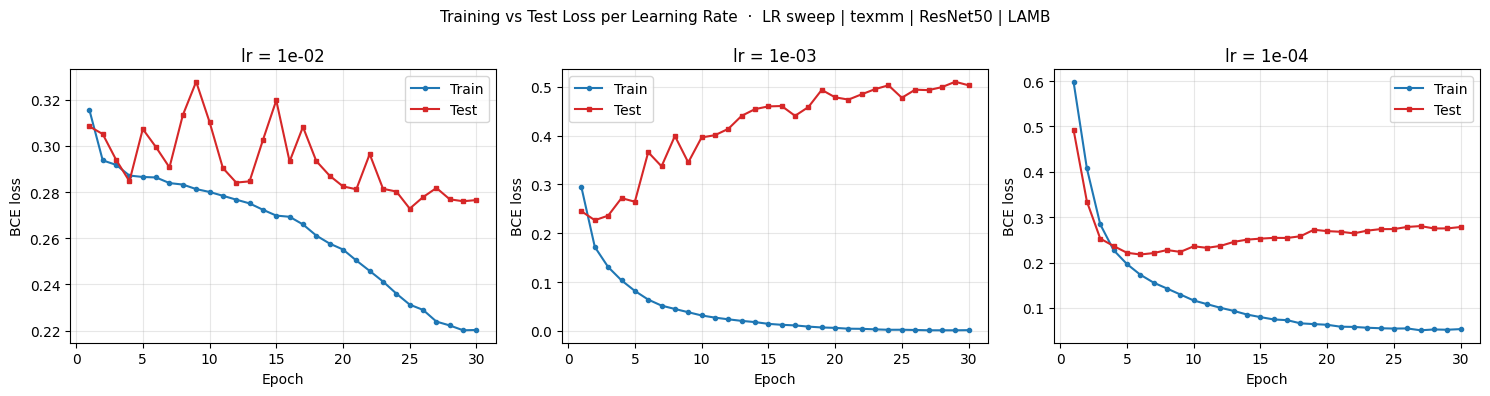

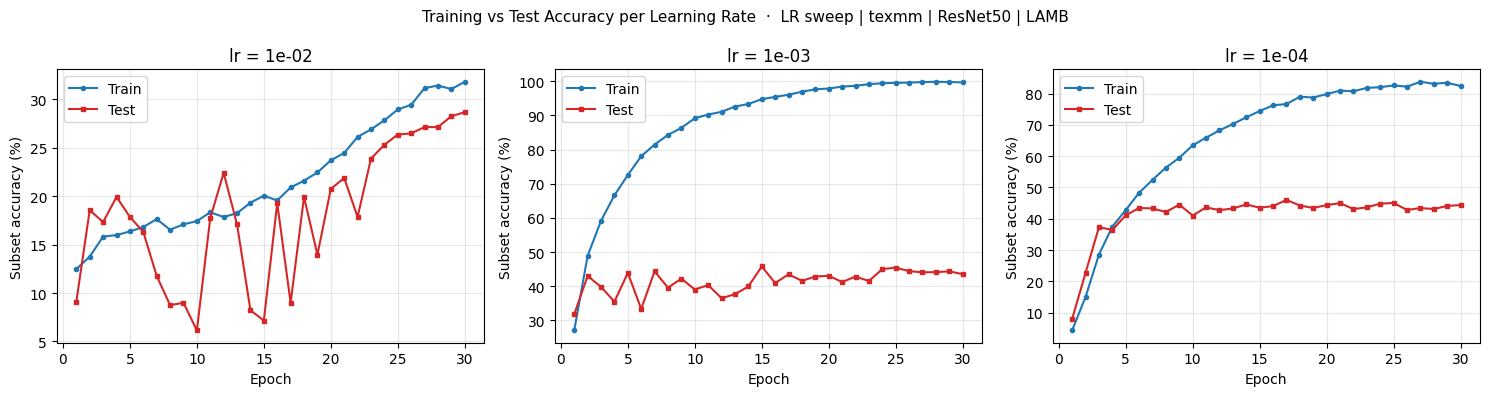

saved loss + accuracy plots -> /content/drive/MyDrive/TexMM_Local


In [ ]:
nlr = len(LR_GRID)
ep = range(1, SWEEP_EPOCHS + 1)

# --- Figure 1: training vs test LOSS per learning rate (one panel per LR) ---
fig, axes = plt.subplots(1, nlr, figsize=(5 * nlr, 4), sharex=True, squeeze=False)
for ax, lr in zip(axes[0], LR_GRID):
    h = sweep_hist[lr]
    ax.plot(ep, h['train_loss'], 'o-', ms=3, color='#1f77b4', label='Train')
    ax.plot(ep, h['test_loss'],  's-', ms=3, color='#d62728', label='Test')
    ax.set_title(f'lr = {lr:.0e}'); ax.set_xlabel('Epoch'); ax.set_ylabel('BCE loss')
    ax.legend(); ax.grid(alpha=0.3)
fig.suptitle('Training vs Test Loss per Learning Rate  ·  ' + RUN_NAME, fontsize=11)
fig.tight_layout()
fig.savefig('/content/lr_sweep_loss.png', dpi=150, bbox_inches='tight'); plt.show()

# --- Figure 2: training vs test ACCURACY per learning rate (separate figure) ---
fig, axes = plt.subplots(1, nlr, figsize=(5 * nlr, 4), sharex=True, squeeze=False)
for ax, lr in zip(axes[0], LR_GRID):
    h = sweep_hist[lr]
    ax.plot(ep, [a * 100 for a in h['train_acc']], 'o-', ms=3, color='#1f77b4', label='Train')
    ax.plot(ep, [a * 100 for a in h['test_acc']],  's-', ms=3, color='#d62728', label='Test')
    ax.set_title(f'lr = {lr:.0e}'); ax.set_xlabel('Epoch'); ax.set_ylabel('Subset accuracy (%)')
    ax.legend(); ax.grid(alpha=0.3)
fig.suptitle('Training vs Test Accuracy per Learning Rate  ·  ' + RUN_NAME, fontsize=11)
fig.tight_layout()
fig.savefig('/content/lr_sweep_acc.png', dpi=150, bbox_inches='tight'); plt.show()

os.makedirs(SAVE_DIR, exist_ok=True)
for src, dst in [('/content/lr_sweep_loss.png', RUN_TAG + '_loss.png'),
                 ('/content/lr_sweep_acc.png',  RUN_TAG + '_acc.png')]:
    shutil.copy(src, os.path.join(SAVE_DIR, dst))
print('saved loss + accuracy plots ->', SAVE_DIR)